# 05 Results on 2025
The final model is **logistic regression v2 with C=0.3**, chosen in notebook 04 on 2024. Nothing is tuned here.

Both the model and the baseline are retrained on 2022–24, then scored on 2025 **once**.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.evaluate import baseline_prob, evaluate, fit_grid_baseline, load_features, podium_hits, time_split
from src.features import MODEL_FEATURES, RAW_DATA_DIR
from src.models import make_logreg

FINAL_C = 0.3  # fixed in notebook 04; do not retune on test

MODEL_COLOR, BASELINE_COLOR = "#2a78d6", "#eb6834"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True})

In [2]:
train, valid, test = time_split(load_features(), include_test=True)
fit_set = pd.concat([train, valid], ignore_index=True)  # 2022-24

model = make_logreg(FINAL_C).fit(fit_set[MODEL_FEATURES], fit_set["Podium"])
test["ModelProb"] = model.predict_proba(test[MODEL_FEATURES])[:, 1]
test["BaselineProb"] = baseline_prob(test, fit_grid_baseline(fit_set))

print(f"fit on {fit_set['Year'].unique()}, {len(fit_set)} rows; test 2025: {test.groupby('Round').ngroups} races")
results = pd.DataFrame({"baseline (grid top 3)": evaluate(test, "BaselineProb"),
                        f"logreg v2 (C={FINAL_C})": evaluate(test, "ModelProb")}).T
results

fit on [2022 2023 2024], 1357 rows; test 2025: 24 races


,hits_per_race,perfect_races_pct,brier
baseline (grid top 3),2.25,33.3,0.0591
logreg v2 (C=0.3),2.25,33.3,0.0593


## Hits per race

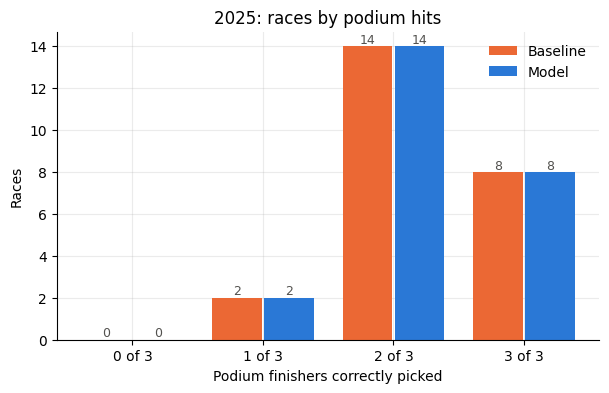

In [3]:
hits = pd.DataFrame({"Baseline": podium_hits(test, "BaselineProb"), "Model": podium_hits(test, "ModelProb")})
counts = pd.DataFrame({k: hits[k].value_counts().reindex(range(4), fill_value=0) for k in hits})

fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(4)
w = 0.38
for i, (name, color) in enumerate([("Baseline", BASELINE_COLOR), ("Model", MODEL_COLOR)]):
    bars = ax.bar(x + (i - 0.5) * (w + 0.02), counts[name], w, color=color, label=name)
    ax.bar_label(bars, fontsize=9, color="#52514e")
ax.set_xticks(x, [f"{n} of 3" for n in range(4)])
ax.set_xlabel("Podium finishers correctly picked")
ax.set_ylabel("Races")
ax.set_title("2025: races by podium hits")
ax.legend(frameon=False)
plt.show()

In [4]:
# Races where model and baseline differ
hits["Diff"] = hits["Model"] - hits["Baseline"]
hits["GrandPrix"] = test.drop_duplicates("Round").set_index(["Year", "Round"])["GrandPrix"]
print(f"Model better in {(hits['Diff'] > 0).sum()} races, worse in {(hits['Diff'] < 0).sum()}")
hits[hits["Diff"] != 0]

Model better in 3 races, worse in 3


Baseline  Model  Diff                  GrandPrix
Year Round                                                  
2025 6             1      2     1           Miami Grand Prix
     7             2      3     1  Emilia Romagna Grand Prix
     15            2      1    -1           Dutch Grand Prix
     17            2      1    -1      Azerbaijan Grand Prix
     19            3      2    -1   United States Grand Prix
     22            1      2     1       Las Vegas Grand Prix

## Calibration
When the model says 30%, does the driver finish on the podium about 30% of the time? Points on the diagonal mean yes.

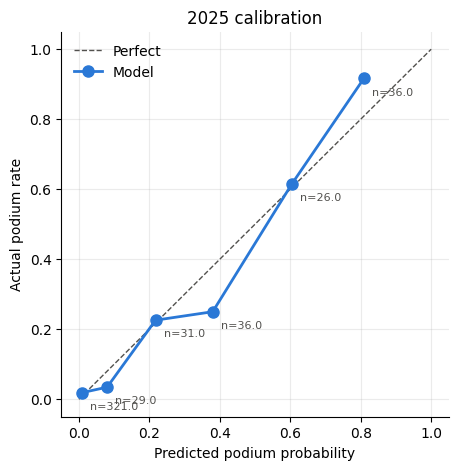

,Predicted,Actual,N
Bin,,,
"(-0.001, 0.05]",0.009,0.019,321
"(0.05, 0.15]",0.080,0.034,29
"(0.15, 0.3]",0.218,0.226,31
"(0.3, 0.5]",0.380,0.250,36
"(0.5, 0.7]",0.605,0.615,26
"(0.7, 1.0]",0.809,0.917,36


In [5]:
bins = [0, 0.05, 0.15, 0.3, 0.5, 0.7, 1.0]
calib = (test.assign(Bin=pd.cut(test["ModelProb"], bins, include_lowest=True))
         .groupby("Bin", observed=True)
         .agg(Predicted=("ModelProb", "mean"), Actual=("Podium", "mean"), N=("Podium", "size")))

fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([0, 1], [0, 1], color="#52514e", lw=1, ls="--", label="Perfect")
ax.plot(calib["Predicted"], calib["Actual"], color=MODEL_COLOR, lw=2, marker="o", ms=8, label="Model")
for _, r in calib.iterrows():
    ax.annotate(f"n={r.N}", (r.Predicted, r.Actual), textcoords="offset points", xytext=(6, -12), fontsize=8, color="#52514e")
ax.set_xlabel("Predicted podium probability")
ax.set_ylabel("Actual podium rate")
ax.set_title("2025 calibration")
ax.legend(frameon=False)
plt.show()
calib.round(3)

## What the model relies on
These are standardized coefficients: bigger bars mean a stronger effect. Negative means a higher value lowers the podium chance, so for grid and rank features lower is better.

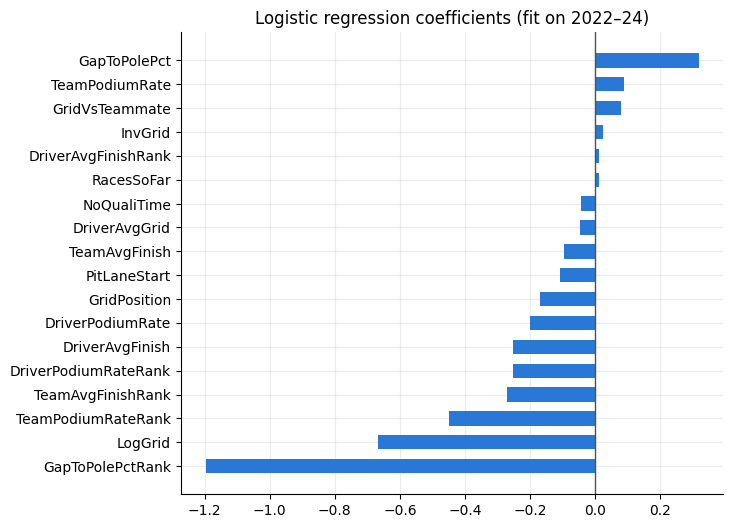

In [6]:
coefs = pd.Series(model[-1].coef_[0], index=model[:-1].get_feature_names_out())
coefs = coefs[~coefs.index.str.startswith("missingindicator")].sort_values()

fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(coefs.index, coefs.values, color=MODEL_COLOR, height=0.6)
ax.axvline(0, color="#52514e", lw=1)
ax.set_title("Logistic regression coefficients (fit on 2022–24)")
plt.show()

## Error analysis
Two kinds of miss:
- **Picked but not on the podium.** A DNF (retirement), or simply beaten.
- **On the podium but not picked.** Usually a driver who came through from further back.

In [7]:
raw = pd.read_csv(RAW_DATA_DIR / "races_2022_2025.csv")[["Year", "Round", "Abbreviation", "Status"]]
test = test.merge(raw, on=["Year", "Round", "Abbreviation"], how="left", validate="one_to_one")
test["Picked"] = test.groupby("Round")["ModelProb"].rank(ascending=False) <= 3

finished = test["Status"].isin(["Finished", "Lapped"]) | test["Status"].str.startswith("+")
false_picks = test[test["Picked"] & (test["Podium"] == 0)]
dnf_picks = false_picks[~finished.loc[false_picks.index]]
print(f"Picked but missed: {len(false_picks)}, of which DNF/DSQ: {len(dnf_picks)}")
dnf_picks[["GrandPrix", "Abbreviation", "GridPosition", "Status", "ModelProb"]].round(2)

Picked but missed: 18, of which DNF/DSQ: 3


,GrandPrix,Abbreviation,GridPosition,Status,ModelProb
280,Dutch Grand Prix,NOR,2.0,Retired,0.79
327,Azerbaijan Grand Prix,PIA,9.0,Retired,0.43
419,Las Vegas Grand Prix,NOR,1.0,Disqualified,0.85


In [8]:
missed = test[~test["Picked"] & (test["Podium"] == 1)].copy()
missed["ModelRank"] = test.groupby("Round")["ModelProb"].rank(ascending=False).loc[missed.index]
print(f"Podiums missed: {len(missed)} of {test['Podium'].sum()}")
print("Missed podium came from grid:", missed["GridPosition"].describe()[["min", "50%", "max"]].to_dict())
missed[["GrandPrix", "Abbreviation", "Team", "GridPosition", "ModelRank", "ModelProb"]].sort_values("GridPosition").round(2)

Podiums missed: 18 of 72
Missed podium came from grid: {'min': 2.0, '50%': 5.0, 'max': 19.0}


,GrandPrix,Abbreviation,Team,GridPosition,ModelRank,ModelProb
320,Azerbaijan Grand Prix,SAI,Williams,2.0,9.0,0.05
281,Dutch Grand Prix,VER,Red Bull,3.0,4.0,0.29
361,United States Grand Prix,LEC,Ferrari,3.0,5.0,0.18
3,Australian Grand Prix,RUS,Mercedes,4.0,4.0,0.37
282,Dutch Grand Prix,HAD,RB,4.0,7.0,0.05
83,Saudi Arabian Grand Prix,LEC,Ferrari,4.0,5.0,0.29
262,Hungarian Grand Prix,RUS,Mercedes,4.0,4.0,0.36
182,Canadian Grand Prix,ANT,Mercedes,4.0,6.0,0.17
323,Azerbaijan Grand Prix,RUS,Mercedes,5.0,4.0,0.25
343,Singapore Grand Prix,NOR,McLaren,5.0,4.0,0.45


## Takeaways
- **2025 test: the model ties the grid baseline.** Both get 2.25 hits per race and 33% perfect races, with Brier 0.0593 vs 0.0591. The model is better in 3 races and worse in 3.
- **The 2024 gain did not hold.** On validation it beat the baseline by 0.04 hits and about 3% on Brier, but 24 races is a small sample, and that edge was within noise.
- **The grid is a very strong baseline.** In 2025, 54 of 72 podium finishers started in the top 3. That leaves little room for a pre-race model.
- **The calibration is good.** Predicted probabilities track actual podium rates, so the probabilities are usable even when the picks match the grid.
- **What can't be predicted:** DNFs and DSQs (Norris at Zandvoort and Las Vegas), and drives from deep on the grid (Verstappen from P19 in Brazil, Antonelli from P17 in Las Vegas, Hülkenberg from P19 at Silverstone).
- **The most useful signal is pure qualifying pace** (gap-to-pole rank), more than the grid slot itself, followed by team form.

**Next ideas:** practice long-run pace, weather (wet races), and a probability-of-DNF feature from team reliability.